<a href="https://colab.research.google.com/github/mayajdias/A05-pca/blob/main/notebook_(7).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [5]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

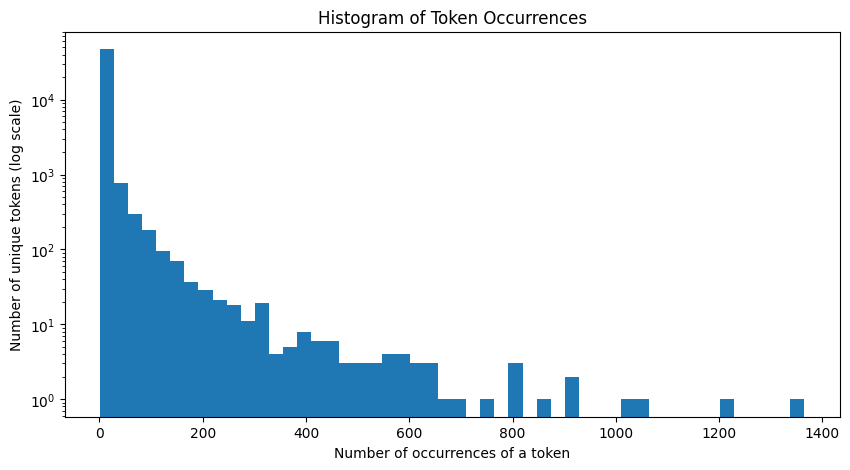

In [6]:
import matplotlib.pyplot as plt

# How many times each unique token appears
counts = list(token_count.values())

plt.figure(figsize=(10, 5))
plt.hist(counts, bins=50, log=True)   # log y-axis, since the data is heavily skewed
plt.xlabel("Number of occurrences of a token")
plt.ylabel("Number of unique tokens (log scale)")
plt.title("Histogram of Token Occurrences")
plt.show()

What I notice: the distribution is extremely right-skewed (a long-tailed, Zipf-like pattern). A huge number of tokens appear only once or a handful of times, while a very small number of tokens appear thousands of times. On a normal linear axis, almost everything piles up in the first bin, which is why the log scale helps. On the log-log version, the shape comes out roughly as a straight downward line, which is the signature of a power law.

This matters for NLP because a small set of frequent tokens carries most of the volume, and most of the vocabulary is rare words, which is why people often filter out very rare (or very common) tokens before modeling.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

df = pd.read_parquet("Phishing_clean.parquet")
y = df["Email Type"]
X = df.drop(columns="Email Type")


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#regression on the one-hot tokens
lr = LinearRegression().fit(X_train, y_train)
print("Train R2:", lr.score(X_train, y_train))
print("Test R2:", lr.score(X_test, y_test))


#largest coefficients in absolute value
coefs = pd.Series(lr.coef_, index=X.columns)
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15))

Train R2: 0.7670143724934355
Test R2: 0.6658718438847919
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
dtype: float64


**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

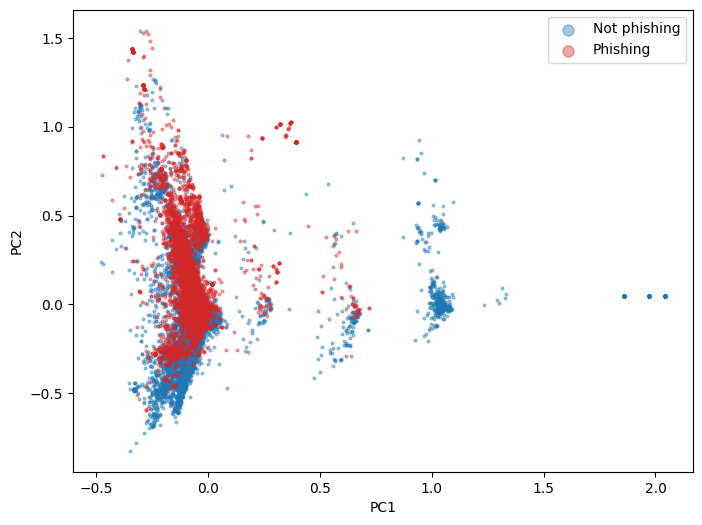

In [10]:
pca2 = PCA(n_components=2)
Z = pca2.fit_transform(X)
plt.figure(figsize=(8, 6))
sns_colors = {0: "tab:blue", 1: "tab:red"}
for label, name in [(0, "Not phishing"), (1, "Phishing")]:
    m = (y == label).values
    plt.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.4, c=sns_colors[label], label=name)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(markerscale=4)
plt.show()

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [11]:
pca = PCA(n_components=2610).fit(X_train)
P_train, P_test = pca.transform(X_train), pca.transform(X_test)
lr_pc = LinearRegression().fit(P_train, y_train)
print("Train R2:", lr_pc.score(P_train, y_train))
print("Test R2:", lr_pc.score(P_test, y_test))

Train R2: 0.7662326827745849
Test R2: 0.6683390643101161


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

Principal components compress thousands of correlated, sparse word indicators into a smaller set of uncorrelated directions that capture most of the variation in the data. Because the components are uncorrelated, the regression is better conditioned and less affected by multicollinearity. We can also drop the low-variance components to reduce dimensionality, which cuts computation and can reduce overfitting and noise, while keeping nearly the same predictive performance (as the R² results show). The tradeoff is interpretability, since each component is a blend of many words rather than a single readable token.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Maya Dias

**Date:** 10/21

In [ ]:
# Your Phase 1 solution to the problem goes here.

#Included above below each question


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 4f92136
- **AI tool and model used:** ChatGPT 6

### *Prompts used

1. Please help me complete phase 2 of the notebook by giving me a numbered list of improvement suggestions on where I may not have answered the prompts correctly. Help me code the new version with the errors corrected

### *AI-proposed changes


1. Improve the token-frequency analysis by displaying the most common tokens and using a logarithmic y-axis for the histogram.
2. Improve the regression analysis by reporting training and test R² and ranking the 15 largest coefficients by absolute magnitude.
3. Add a confusion matrix and classification metrics to evaluate phishing predictions.
4. Standardize every token column before performing PCA.
5. Add a log-log plot and interpret the token distribution as a power law.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Display common tokens and improve the histogram | Accept | The most common tokens provide useful examples, and a logarithmic y-axis makes the long-tailed distribution easier to interpret. Verify that the histogram displays correctly. |
| 2. Report training/test R² and rank coefficients | Accept | These directly answer Q2 and make model fit and influential tokens easier to evaluate. Verify that the scores print and the coefficient ranking is sorted by absolute value. |
| 3. Add a confusion matrix and classification metrics | Reject | The assignment asks for linear regression and R², not a separate classification evaluation. These additions are unnecessary for answering the stated questions. |
| 4. Standardize all token columns before PCA | Reject | This changes the specified PCA approach and can alter the interpretation of binary token features. Keep the original features for consistency with the assignment. |
| 5. Add a log-log plot and claim an exact power law | Modify | A log-log plot may help explore the distribution, but visual linearity does not prove a power law. Retain the histogram and describe the pattern cautiously as long-tailed or Zipf-like. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Total token occurrences: 276949
Number of unique tokens: 48691

20 most common tokens:
new: 1365
date: 1202
get: 1052
please: 1022
enron: 927
like: 923
2002: 869
would: 806
one: 798
message: 795
call: 740
free: 691
software: 680
dear: 651
know: 644
email: 629
url:: 625
time: 609
start: 604
linguistics: 598


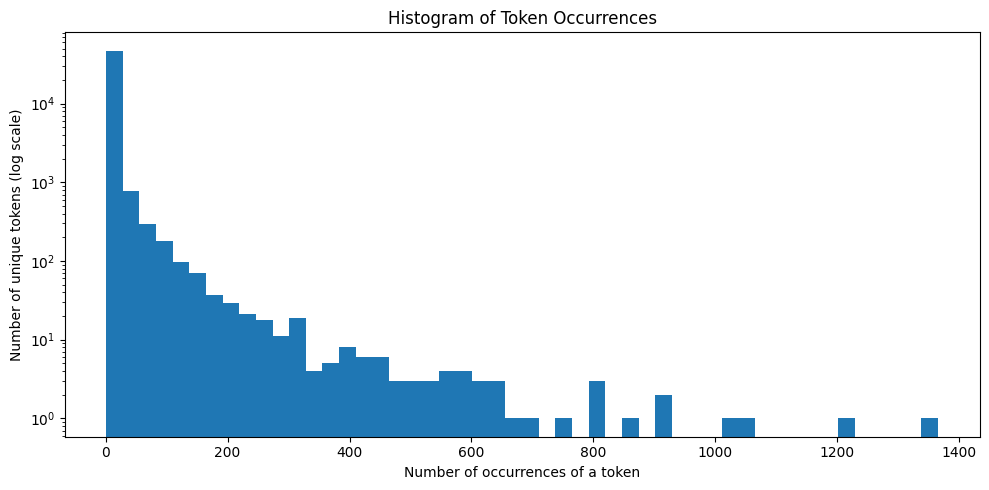


Q2: Linear Regression
Training R²: 0.7670143724934355
Test R²: 0.6658718438847919

15 tokens with the largest absolute coefficients:
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978


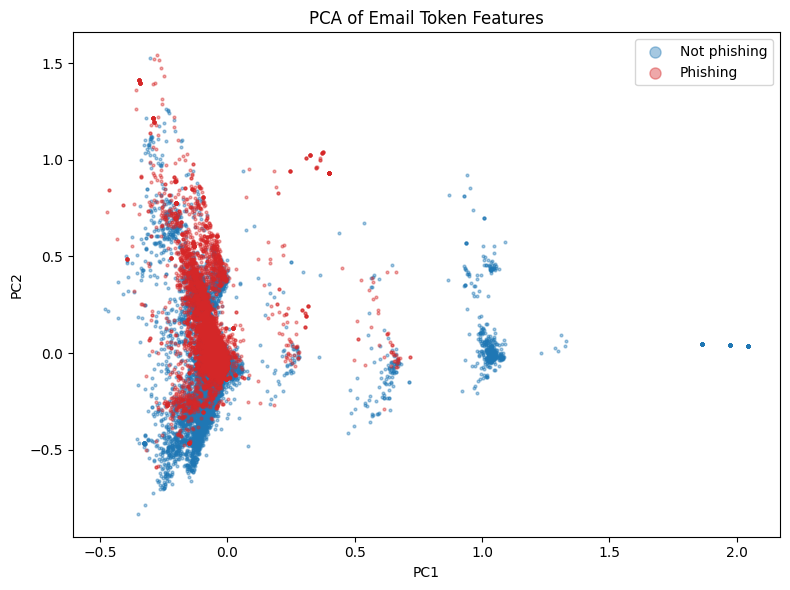


Q3: Explained variance ratio
[0.01113089 0.00861141]
Total variance explained by two components: 0.019742306156686103

Q4: PCA Regression
Training R²: 0.7662326827745849
Test R²: 0.6683390643101164
Variance explained by 2,610 components: 0.9998620409568273

Q5: Principal components transform the original token
features into uncorrelated combinations of features.
This can reduce multicollinearity and allow dimensionality
reduction, potentially reducing computation and overfitting.
However, individual components are less interpretable than
the original word features. Compare the training and test
R² values to assess predictive performance.



In [12]:
# Your Phase 2 solution to the problem goes here.
# Phase 2: AI-assisted solution
# Questions 1-5

import pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA


# --------------------------------------------------
# Q1: Token frequency distribution
# --------------------------------------------------

with open("all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print("Total token occurrences:", len(all_tokens))
print("Number of unique tokens:", len(token_count))
print("\n20 most common tokens:")
for token, count in token_freq[:20]:
    print(f"{token}: {count}")

counts = list(token_count.values())

plt.figure(figsize=(10, 5))
plt.hist(counts, bins=50, log=True)
plt.xlabel("Number of occurrences of a token")
plt.ylabel("Number of unique tokens (log scale)")
plt.title("Histogram of Token Occurrences")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Q2: Linear regression on one-hot-encoded tokens
# --------------------------------------------------

df = pd.read_parquet("Phishing_clean.parquet")

y = df["Email Type"]
X = df.drop(columns=["Email Type"])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

lr = LinearRegression()
lr.fit(X_train, y_train)

print("\nQ2: Linear Regression")
print("Training R²:", lr.score(X_train, y_train))
print("Test R²:", lr.score(X_test, y_test))

coefs = pd.Series(lr.coef_, index=X.columns)
top_coefs = coefs.reindex(
    coefs.abs().sort_values(ascending=False).index
).head(15)

print("\n15 tokens with the largest absolute coefficients:")
print(top_coefs.to_string())


# --------------------------------------------------
# Q3: PCA with two components
# --------------------------------------------------

pca2 = PCA(n_components=2)
Z = pca2.fit_transform(X)

plt.figure(figsize=(8, 6))

colors = {0: "tab:blue", 1: "tab:red"}
names = {0: "Not phishing", 1: "Phishing"}

for label in [0, 1]:
    mask = (y == label).to_numpy()
    plt.scatter(
        Z[mask, 0],
        Z[mask, 1],
        s=4,
        alpha=0.4,
        c=colors[label],
        label=names[label]
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Email Token Features")
plt.legend(markerscale=4)
plt.tight_layout()
plt.show()

print("\nQ3: Explained variance ratio")
print(pca2.explained_variance_ratio_)
print("Total variance explained by two components:",
      pca2.explained_variance_ratio_.sum())


# --------------------------------------------------
# Q4: Regression using the first 2,610 components
# --------------------------------------------------

pca = PCA(n_components=2610)
P_train = pca.fit_transform(X_train)
P_test = pca.transform(X_test)

lr_pc = LinearRegression()
lr_pc.fit(P_train, y_train)

print("\nQ4: PCA Regression")
print("Training R²:", lr_pc.score(P_train, y_train))
print("Test R²:", lr_pc.score(P_test, y_test))
print(
    "Variance explained by 2,610 components:",
    pca.explained_variance_ratio_.sum()
)


# --------------------------------------------------
# Q5: Interpretation
# --------------------------------------------------

print("""
Q5: Principal components transform the original token
features into uncorrelated combinations of features.
This can reduce multicollinearity and allow dimensionality
reduction, potentially reducing computation and overfitting.
However, individual components are less interpretable than
the original word features. Compare the training and test
R² values to assess predictive performance.
""")

### *Reflection on AI assistance


[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements in this revision are clearer outputs and more systematic evaluation. In Q1, the code displays the 20 most common tokens and uses a logarithmic y-axis to make the long-tailed distribution easier to inspect. In Q2, it reports both training and test R² and ranks the 15 largest coefficients by absolute magnitude while preserving their signs. The PCA analysis also reports explained variance, providing additional information for interpreting the dimensionality reduction.

AI assistance has limitations. The appearance of a long-tailed token distribution does not prove an exact power law. Similarly, regression coefficients indicate conditional associations within the fitted model, not causal relationships. Standardizing binary token indicators could also change the intended PCA analysis, so I rejected that recommendation. Adding classification metrics was unnecessary because the assignment specifically requests regression R². These decisions keep the analysis focused on the original questions.

The code provides reproducible train-test splitting with a fixed random seed. However, the final numerical results must be verified by running the notebook with the course datasets. I would inspect the token histogram, check that the coefficient ranking is ordered correctly, compare training and test R² for both regression models, and examine the PCA scatter plot. I would also confirm that all cells execute successfully and replace the Phase 1 commit placeholder with the actual Git commit SHA before submission.